# Annual Deforestation – Amazônia Legal (Hansen GFC v1.13)

Yearly forest loss (2011–2025) inside the Brazilian Legal Amazon, from the Hansen Global Forest Change dataset,
compared with MapBiomas Collection 10 deforestation (steps 9–11) and the official INPE PRODES rates (step 11).

**How to run:** run the cells from top to bottom. The heavy calculation runs as a background export on
Earth Engine's servers (step 6). Wait until step 7 shows `COMPLETED`, then run step 8.
After that has finished once, you only need steps 1, 2 and 8 to reload the results.

## 1. Imports

In [9]:
import time
from pprint import pprint

import ee
import geemap
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

## 2. Connect to Earth Engine
`PROJECT` is your Earth Engine Cloud project ID (shown at the top of the Code Editor, code.earthengine.google.com).
If you have never logged in on this computer, `ee.Authenticate()` opens a browser window once.

In [10]:
PROJECT = 'ee-felipecoelhocosta'

try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)

# Should print something like [{'id': 'projects/ee-felipecoelhocosta/assets', ...}]
pprint(ee.data.getAssetRoots())

## 3. Map

In [11]:
Map = geemap.Map(center=[-4, -58], zoom=5)
Map

Map(center=[-4, -58], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tra…

## 4. Legal Amazon boundary
The original shapefile has ~330,000 vertices (~9 MB), which exceeds Earth Engine's 10 MB request limit.
Simplifying with a ~55 m tolerance reduces it to ~1 MB with no meaningful loss for an area of ~5 million km².

In [12]:
amazonia_shp = '/Users/felipecoelhocostageo/Documents/geoData/gis/amazonia/Limites_Amazonia_Legal_2024_shp/Limites_Amazonia_Legal_2024.shp'

amazonia_gdf = gpd.read_file(amazonia_shp).to_crs(4326)
amazonia_gdf['geometry'] = amazonia_gdf.simplify(0.0005, preserve_topology=True)  # ~55 m tolerance
amazonia = geemap.gdf_to_ee(amazonia_gdf)

Map.addLayer(amazonia, {}, 'Amazonia Legal Brasileira', True, 0.7)

## 5. Hansen forest loss and loss area per year (2011–2025)
`lossyear` = year of loss (1 = 2001 … 25 = 2025); `loss` = 1 where forest was lost.
Only loss from 2011 onwards (`lossyear` ≥ 11) is kept, because the GFW methodology was adjusted in 2011.
This cell only *defines* the calculation; nothing is computed until the export in step 6.

In [13]:
gfc = ee.Image('UMD/hansen/global_forest_change_2025_v1_13')
lossYear = gfc.select('lossyear')

# Analysis period: 2011–2025 only (lossyear 11–25). Loss before 2011 is set to 0,
# so it is left out of both the map layer and the area calculation.
FIRST_YEAR, LAST_YEAR = 11, 25
lossImage = gfc.select('loss').And(lossYear.gte(FIRST_YEAR))

# Show loss year on the map (yellow = 2011, red = 2025).
# selfMask() makes every zoomed-out map pixel fully opaque if it contains ANY loss, so the whole
# Amazon looks saturated. Masking with the 0/1 loss band instead lets opacity follow the share
# of the area that was lost: scattered loss looks faint, dense loss looks solid.
lossVis = lossYear.updateMask(lossImage).clip(amazonia)
Map.addLayer(lossVis,
             {'min': FIRST_YEAR, 'max': LAST_YEAR, 'palette': ['yellow', 'orange', 'red']},
             'Loss year', True, 0.8)  # last argument = layer opacity

# Band 0 = loss area (ha) per pixel, band 1 = loss year; only 2011–2025 loss pixels are processed
lossAreaImage = lossImage.multiply(ee.Image.pixelArea()).divide(10000)
image_2 = lossAreaImage.addBands(lossYear).updateMask(lossImage)

lossByYear = image_2.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='group'),
    geometry=amazonia.geometry(),
    scale=30,
    maxPixels=1e13,
    tileScale=4,
)

# Turn [{'group': 11, 'sum': ...}, ...] into {'2011': ..., '2012': ..., ...}
def process(el):
    d = ee.Dictionary(el)
    return ee.List([ee.Number(d.get('group')).format('20%02d'), d.get('sum')])

statsDictionary = ee.Dictionary(ee.List(lossByYear.get('groups')).map(process).flatten())

In [14]:
# Legend for both layers, drawn as a small HTML box so we control the ticks
# (geemap's add_colorbar picks ticks automatically, giving overlapping labels like 2012.5).
import ipywidgets as widgets
from ipyleaflet import WidgetControl

TICKS = [2011, 2015, 2019, 2023, 2025]   # start of each presidential term + last year
Y0, Y1 = 2011, 2025

tick_labels = ''.join(
    f'<span style="position:absolute; left:{(y - Y0) / (Y1 - Y0) * 100:.1f}%; '
    f'transform:translateX(-50%);">{y}</span>'
    for y in TICKS
)

legend_html = f'''
<div style="background:white; padding:8px 20px 10px; border-radius:4px;
            font-family:sans-serif; font-size:12px; color:#222; width:260px;">
  <div style="font-weight:bold; margin-bottom:6px;">Legenda</div>

  <div style="display:flex; align-items:center; gap:6px; margin-bottom:8px;">
    <span style="display:inline-block; width:18px; height:12px;
                 border:2px solid #000; background:rgba(0,0,0,0.3);"></span>
    Amazônia Legal
  </div>

  <div style="margin-bottom:4px;">Ano do desmatamento</div>
  <div style="height:12px; background:linear-gradient(to right, yellow, orange, red);"></div>
  <div style="position:relative; height:16px; margin-top:2px;">{tick_labels}</div>
</div>
'''

legend = WidgetControl(widget=widgets.HTML(legend_html), position='bottomright')
Map.add(legend)

## 6. Run the calculation as a background export
The Legal Amazon is too large for an interactive `getInfo()` (it times out), so the result is saved
as an Earth Engine asset. You can close the notebook while it runs.

In [39]:
asset_id = f'projects/{PROJECT}/assets/Amazonia_loss_by_year'

task = ee.batch.Export.table.toAsset(
    collection=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([0, 0]), statsDictionary)]),
    description='Amazonia_loss_by_year',
    assetId=asset_id,
    overwrite=True,
)
task.start()
print('Export started:', asset_id)

Export started: projects/ee-felipecoelhocosta/assets/Amazonia_loss_by_year


## 7. Check progress
Re-run this cell until it says `COMPLETED` (may take 10 minutes to an hour).
You can also follow it in the **Tasks** tab of the Code Editor.

In [41]:
status = task.status()
print(status['state'])
if status['state'] == 'FAILED':
    print(status.get('error_message'))

COMPLETED


## 8. Load results and plot
Works any time after the export has completed — even after restarting the kernel (run steps 1 and 2 first).

year
2011    1.307234e+06
2012    1.875740e+06
2013    1.381704e+06
2014    1.972596e+06
2015    1.752583e+06
2016    4.484444e+06
2017    3.808282e+06
2018    2.465508e+06
2019    2.312245e+06
2020    2.879232e+06
2021    2.512439e+06
2022    2.846002e+06
2023    2.450688e+06
2024    4.077210e+06
2025    2.548274e+06
Name: loss_ha, dtype: float64


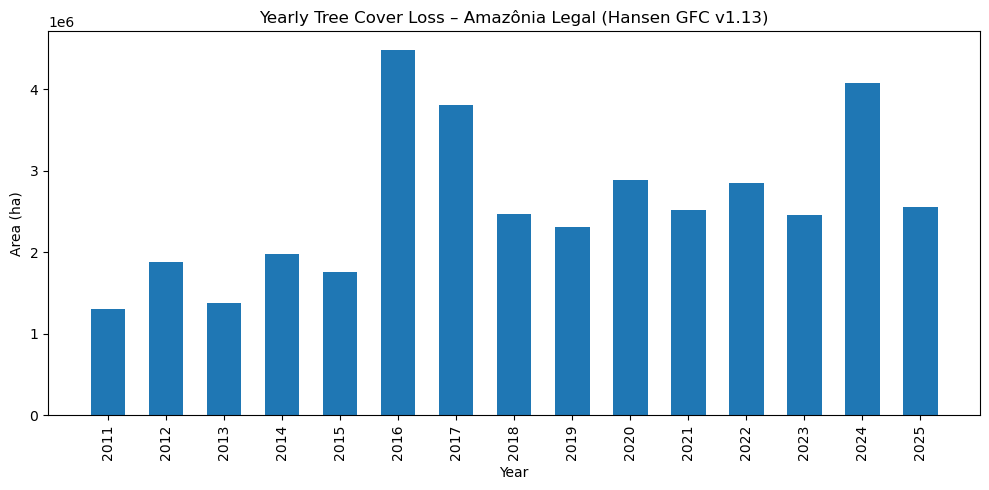

In [15]:
asset_id = f'projects/{PROJECT}/assets/Amazonia_loss_by_year'

stats = ee.FeatureCollection(asset_id).first().toDictionary().getInfo()
loss = pd.Series(stats, name='loss_ha').sort_index()
loss.index.name = 'year'
print(loss)

loss.to_csv('amazonia_loss_by_year.csv')

plt.figure(figsize=(10, 5))
plt.bar(loss.index, loss.values, width=0.6)
plt.title('Yearly Tree Cover Loss – Amazônia Legal (Hansen GFC v1.13)')
plt.ylabel('Area (ha)')
plt.xlabel('Year')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('amazonia_loss_by_year.png', dpi=150)
plt.show()

## 9. MapBiomas Collection 10 – deforestation per year (2011–2025)
MapBiomas' *deforestation and secondary vegetation* product has one band per year (`classification_YYYY`):

| value | meaning |
|---|---|
| 1 | anthropic use |
| 2 | primary native vegetation |
| 3 | secondary native vegetation |
| **4** | **suppression of primary vegetation (deforestation)** |
| 5 | recovery to secondary vegetation |
| **6** | **suppression of secondary vegetation** |
| 7 | other transitions |

Classes 4 and 6 are counted separately. Unlike Hansen (tree cover loss, 2001–2025), MapBiomas covers **all native
vegetation** (forest, savanna/cerrado, grassland), is specific to Brazil and currently goes up to 2024.
Its definitions differ from Hansen's, so expect different numbers.
As in step 5, this cell only *defines* the calculation.

In [16]:
mb = ee.Image('projects/mapbiomas-public/assets/brazil/lulc/collection10/'
              'mapbiomas_brazil_collection10_deforestation_secondary_vegetation_v2')

MB_YEARS = list(range(2011, 2025))   # Collection 10 ends in 2024

# Map: year of the latest MapBiomas deforestation (class 4 or 6), same palette as the Hansen layer
mbYear = ee.ImageCollection([
    ee.Image.constant(y).int().updateMask(
        mb.select(f'classification_{y}').eq(4).Or(mb.select(f'classification_{y}').eq(6)))
    for y in MB_YEARS
]).max().clip(amazonia)
Map.addLayer(mbYear, {'min': 2011, 'max': 2025, 'palette': ['yellow', 'orange', 'red']},
             'MapBiomas deforestation year', False, 0.8)   # off by default; tick it in the layer menu

# One band per year and class with the area in ha, then sum each band in a single reduceRegion
pixelHa = ee.Image.pixelArea().divide(10000)
bands = []
for y in MB_YEARS:
    c = mb.select(f'classification_{y}')
    bands.append(pixelHa.updateMask(c.eq(4)).rename(f'primary_{y}'))
    bands.append(pixelHa.updateMask(c.eq(6)).rename(f'secondary_{y}'))
mbAreaImage = ee.Image.cat(bands)

mbStats = mbAreaImage.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=amazonia.geometry(),
    scale=30,
    maxPixels=1e13,
    tileScale=4,
)

## 10. Run the MapBiomas calculation as a background export
Same approach as step 6. Re-run the status cell until it says `COMPLETED`.

In [16]:
mb_asset_id = f'projects/{PROJECT}/assets/Amazonia_mapbiomas_defor_by_year'

mb_task = ee.batch.Export.table.toAsset(
    collection=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([0, 0]), mbStats)]),
    description='Amazonia_mapbiomas_defor_by_year',
    assetId=mb_asset_id,
    overwrite=True,
)
mb_task.start()
print('Export started:', mb_asset_id)

Export started: projects/ee-felipecoelhocosta/assets/Amazonia_mapbiomas_defor_by_year


In [19]:
status = mb_task.status()
print(status['state'])
if status['state'] == 'FAILED':
    print(status.get('error_message'))

RUNNING


## 11. Load MapBiomas results and compare with Hansen and PRODES
Works any time after the export has completed (run steps 1 and 2 first).

**PRODES** (INPE) is Brazil's official annual clear-cut deforestation rate for the Legal Amazon. The values are
in `amazonia_prodes_defor_by_year.csv` (km² and ha), taken from INPE/TerraBrasilis: consolidated rates for 2011–2025
(2025 = 5,731 km², consolidated in 2026). A PRODES "year" runs from 1 August of the previous year to 31 July,
so it does not line up exactly with Hansen's and MapBiomas' calendar years. PRODES only maps primary forest,
with a 6.25 ha minimum mapping unit.

      primary_ha  secondary_ha   total_ha
year                                     
2011   1120004.0      298133.0  1418137.0
2012   1200535.0      354349.0  1554884.0
2013   1459015.0      429058.0  1888073.0
2014   1320254.0      421707.0  1741961.0
2015   1526997.0      471944.0  1998941.0
2016   1514866.0      466263.0  1981129.0
2017   1276055.0      386832.0  1662888.0
2018   1311210.0      393119.0  1704329.0
2019   1927333.0      475072.0  2402405.0
2020   1934213.0      408255.0  2342468.0
2021   2048429.0      441588.0  2490017.0
2022   2192221.0      614964.0  2807185.0
2023   1918475.0      759069.0  2677544.0
2024   1342787.0      305126.0  1647913.0
year
2011     641800
2012     457100
2013     589100
2014     501200
2015     620700
2016     789300
2017     694700
2018     753600
2019    1012900
2020    1085100
2021    1303800
2022    1159400
2023     906400
2024     651800
2025     573100
Name: prodes_ha, dtype: int64


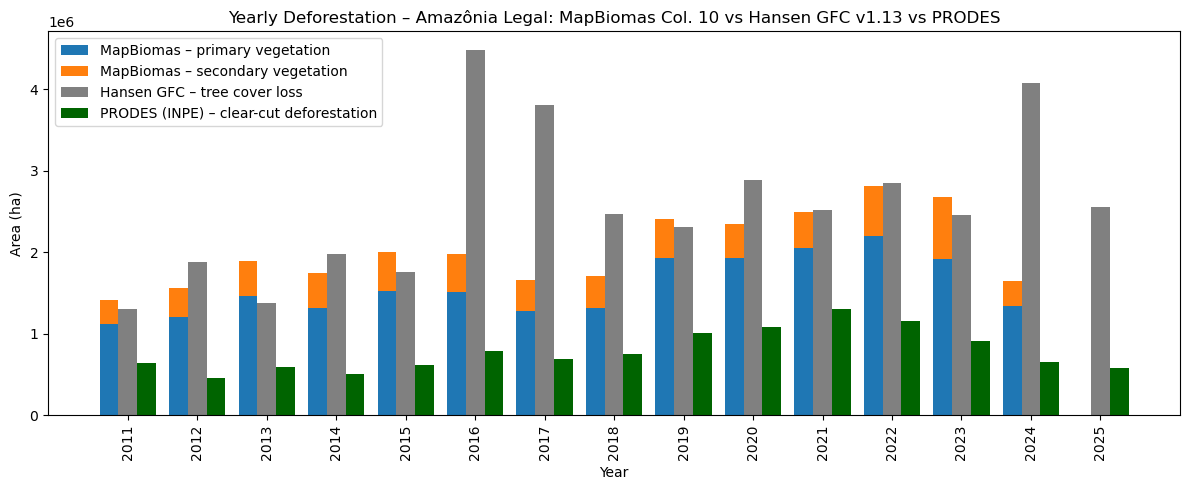

In [17]:
mb_asset_id = f'projects/{PROJECT}/assets/Amazonia_mapbiomas_defor_by_year'

raw = ee.FeatureCollection(mb_asset_id).first().toDictionary().getInfo()
mb_defor = pd.DataFrame({
    'primary_ha':   {int(k.split('_')[1]): v for k, v in raw.items() if k.startswith('primary_')},
    'secondary_ha': {int(k.split('_')[1]): v for k, v in raw.items() if k.startswith('secondary_')},
}).sort_index()
mb_defor.index.name = 'year'
mb_defor['total_ha'] = mb_defor['primary_ha'] + mb_defor['secondary_ha']
print(mb_defor.round(0))
mb_defor.to_csv('amazonia_mapbiomas_defor_by_year.csv')

# Hansen results from step 8 (read from the CSV so this cell also works after a kernel restart)
hansen = pd.read_csv('amazonia_loss_by_year.csv', index_col='year')['loss_ha']

# PRODES official rates (INPE), see the note above
prodes = pd.read_csv('amazonia_prodes_defor_by_year.csv', index_col='year')['prodes_ha']
print(prodes)

fig, ax = plt.subplots(figsize=(12, 5))
W = 0.27   # bar width; three bars per year
ax.bar(mb_defor.index - W, mb_defor['primary_ha'], width=W, label='MapBiomas – primary vegetation')
ax.bar(mb_defor.index - W, mb_defor['secondary_ha'], width=W, bottom=mb_defor['primary_ha'],
       label='MapBiomas – secondary vegetation')
ax.bar(hansen.index, hansen.values, width=W, color='grey', label='Hansen GFC – tree cover loss')
ax.bar(prodes.index + W, prodes.values, width=W, color='darkgreen', label='PRODES (INPE) – clear-cut deforestation')
ax.set_title('Yearly Deforestation – Amazônia Legal: MapBiomas Col. 10 vs Hansen GFC v1.13 vs PRODES')
ax.set_ylabel('Area (ha)')
ax.set_xlabel('Year')
ax.set_xticks(range(2011, 2026))
ax.tick_params(axis='x', rotation=90)
ax.legend()
plt.tight_layout()
plt.savefig('amazonia_mapbiomas_vs_hansen.png', dpi=150)
# High-resolution exports for the blog (PNG) and for editing/print (vector SVG and PDF)
plt.savefig('amazonia_mapbiomas_hansen_prodes.png', dpi=300)
plt.savefig('amazonia_mapbiomas_hansen_prodes.svg')
plt.savefig('amazonia_mapbiomas_hansen_prodes.pdf')
plt.show()

## Notes
- Each Hansen release reprocesses some earlier years, so don't mix numbers from v1.9 (2021) with v1.13.
- Loss detection improved after ~2011; UMD advises caution when comparing early and recent years.
- `geemap.zonal_statistics_by_group` and the old Amanã buffer cells were removed: the zonal statistics
  call cannot handle an area this large, and the Amanã variables are no longer defined.
- MapBiomas Collection 10 (v2 of the deforestation asset) ends in 2024; Collection 9 assets are under
  `projects/mapbiomas-public/assets/brazil/lulc/collection9/`. Don't mix numbers from different collections.

- PRODES values are typed in from INPE's technical notes / TerraBrasilis (not computed here). INPE first publishes
  an *estimate* (e.g. 5,796 km² for 2025, Oct 2025) and replaces it with the *consolidated* rate the following year.
  Update `amazonia_prodes_defor_by_year.csv` when a new consolidated rate comes out.